In [1]:
import numpy as np # allows for efficient calculations and manipulation with arrays
import pandas as pd # allows for the use of data frames and application of data science
import matplotlib.pyplot as plt # used for object-oriented plotting or general plotting
from matplotlib.lines import Line2D # allows to manually change the objects that appear in the legend
import seaborn as sns # allows for visualizations

sns.set_style('darkgrid')
import warnings
pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')

In [2]:
met_df = pd.read_csv("met_only_data/booster_only.csv", skiprows=5, header=1)

In [3]:
met_df

,[run number],init-microglia,exercise,fortify-probability,metabolic-booster,eat-probability,lactate-probability,added-glucose,init-vessels,init-plaque,[step],global-integrity
0,4,10,none,0.1,none,0.1,0.2,2400,5,3,0,73.312850
1,9,10,none,0.1,none,0.1,0.2,2400,5,3,0,74.922541
2,7,10,none,0.1,none,0.1,0.2,2400,5,3,0,74.999112
3,5,10,none,0.1,none,0.1,0.2,2400,5,3,0,74.980033
4,8,10,none,0.1,none,0.1,0.2,2400,5,3,0,76.019772
...,...,...,...,...,...,...,...,...,...,...,...,...
657145,74,10,none,0.1,daily,0.1,0.2,2400,5,3,8757,53.490702
657146,74,10,none,0.1,daily,0.1,0.2,2400,5,3,8758,53.490702
657147,74,10,none,0.1,daily,0.1,0.2,2400,5,3,8759,53.490702
657148,74,10,none,0.1,daily,0.1,0.2,2400,5,3,8760,53.490702


In [4]:
# keep only columns related to BBB integrity and met booster amount
met_df = met_df.filter(items=["[run number]", "metabolic-booster", "[step]", "global-integrity"])

In [5]:
met_df

,[run number],metabolic-booster,[step],global-integrity
0,4,none,0,73.312850
1,9,none,0,74.922541
2,7,none,0,74.999112
3,5,none,0,74.980033
4,8,none,0,76.019772
...,...,...,...,...
657145,74,daily,8757,53.490702
657146,74,daily,8758,53.490702
657147,74,daily,8759,53.490702
657148,74,daily,8760,53.490702


In [6]:
# declare sequence for each tiem step, from 0 to 8760
step_seq = np.arange(0, 8760)

In [7]:
# split data into each metabolic booster intensity
none_df = met_df[met_df["metabolic-booster"] == "none"]
mid_df  = met_df[met_df["metabolic-booster"] == "twice per week"]
high_df = met_df[met_df["metabolic-booster"] == "daily"]

In [8]:
none_avg = [(none_df[none_df['[step]'] == i]['global-integrity']).mean() for i in step_seq]
mid_avg  = [(mid_df[mid_df['[step]'] == i]['global-integrity']).mean() for i in step_seq]
high_avg = [(high_df[high_df['[step]'] == i]['global-integrity']).mean() for i in step_seq]

In [9]:
# list of ticks represenented as day value
day_vals = [i/24 for i in step_seq]

In [10]:
# working dataframe for data analysis for the met booster data
plot_df = pd.DataFrame(
            {'ticks':step_seq,
             'day':day_vals,
             "none_mean":none_avg,
             "mid_mean":mid_avg,
             "high_mean":high_avg})


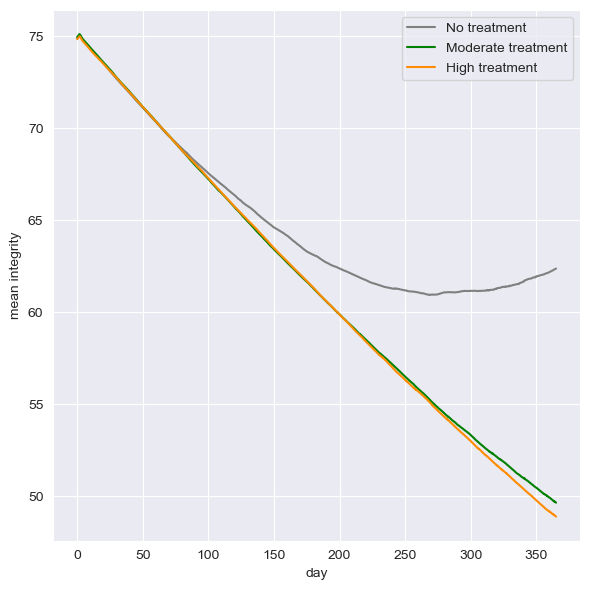

In [11]:
# plot data
fig, ax = plt.subplots(figsize=(6,6))

sns.lineplot(plot_df, x='day',y='none_mean', label='No treatment',color='grey')
sns.lineplot(plot_df, x='day',y='mid_mean', label='Moderate treatment',color='g')
sns.lineplot(plot_df, x='day',y='high_mean', label='High treatment',color='darkorange')

plt.ylabel("mean integrity")
plt.tight_layout()